In [269]:
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm.notebook import trange, tqdm
import numpy as np
import matplotlib.pyplot as plt
import time
import pandas as pd
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
import scipy.io as sio
import pandas as pd
import numpy as np

import pandas as pd

In [270]:
# Carica il file di testo (rileva automaticamente i nomi delle colonne dalla prima riga)
df = pd.read_csv('Dataset_BH_distribution.txt', sep=r'\s+')

# 1. Estrai la lista dei nomi delle colonne in una variabile
column_names = df.columns.tolist()

print("Variabile column_names creata:")
print(column_names)

print("\nAnteprima dei dati caricati:")
print(df.tail(100))

Variabile column_names creata:
['B_magn_T', 'TPU_L_mm', 't_index', 't_val_s', 'x_coord_m', 'H_val_Am', 'B_val_T']

Anteprima dei dati caricati:
        B_magn_T  TPU_L_mm  t_index  t_val_s  x_coord_m       H_val_Am  \
872540       1.2        40       97  0.04224   0.034056   11235.833619   
872541       1.2        40       97  0.04224   0.035629    9256.116355   
872542       1.2        40       97  0.04224   0.036923    6805.273151   
872543       1.2        40       97  0.04224   0.038000    3550.060193   
872544       1.2        40       98  0.04268   0.000000  117243.533350   
...          ...       ...      ...      ...        ...            ...   
872635       1.2        40      101  0.04400   0.032298   13144.772349   
872636       1.2        40      101  0.04400   0.034056   11299.419729   
872637       1.2        40      101  0.04400   0.035629    9317.507699   
872638       1.2        40      101  0.04400   0.036923    6848.695229   
872639       1.2        40      101  0.044

In [271]:
# original  dataset shape

print("Shape del dataset:", df.shape)

# extract the last column name
nome_ultima_colonna = df.columns[-1]

df_estratto = df[['B_magn_T','TPU_L_mm','t_index','x_coord_m' ,'H_val_Am',nome_ultima_colonna]]

print("Shape del dataset estratto:", df_estratto.shape)

Shape del dataset: (872640, 7)
Shape del dataset estratto: (872640, 6)


In [272]:
# create the dataset for the NN
# ho 20 punti sull'asse x

df_filtrato = df_estratto[df_estratto['t_index'] == 1]
print("Shape del dataset filtrato:", df_filtrato.shape)
print(df_filtrato.iloc[0:100])

Shape del dataset filtrato: (8640, 6)
      B_magn_T  TPU_L_mm  t_index  x_coord_m  H_val_Am  B_val_T
0          0.0        20        1   0.000000       0.0      0.0
1          0.0        20        1   0.000533       0.0      0.0
2          0.0        20        1   0.001180       0.0      0.0
3          0.0        20        1   0.001965       0.0      0.0
4          0.0        20        1   0.002917       0.0      0.0
...        ...       ...      ...        ...       ...      ...
9595       0.0        25        1   0.000000       0.0      0.0
9596       0.0        25        1   0.000668       0.0      0.0
9597       0.0        25        1   0.001462       0.0      0.0
9598       0.0        25        1   0.002422       0.0      0.0
9599       0.0        25        1   0.003582       0.0      0.0

[100 rows x 6 columns]


In [273]:
# rremove the rows where B_magn_T is zero

df_senza_zero = df_filtrato[df_filtrato['B_magn_T'] != 0]

In [274]:
print(df_senza_zero.shape)
print(df_senza_zero.iloc[0:100])

(8208, 6)
       B_magn_T  TPU_L_mm  t_index  x_coord_m      H_val_Am   B_val_T
43632  0.063158        20        1   0.000000   5511.493005  0.046150
43633  0.063158        20        1   0.000533   8645.906537  0.074075
43634  0.063158        20        1   0.001180  10368.532991  0.089480
43635  0.063158        20        1   0.001965  10892.623336  0.094368
43636  0.063158        20        1   0.002917  10724.646635  0.092789
...         ...       ...      ...        ...           ...       ...
53227  0.063158        25        1   0.000000   5348.208016  0.044722
53228  0.063158        25        1   0.000668   8192.544184  0.070021
53229  0.063158        25        1   0.001462   9633.804329  0.082910
53230  0.063158        25        1   0.002422   9937.354406  0.085624
53231  0.063158        25        1   0.003582   9545.425073  0.082119

[100 rows x 6 columns]


In [275]:
# df_filtrato is our dataset: DECIDES the INPUTS and OUTPUTS

# INPUT:  TPU_L_mm, x_coord_m, B_val_T
x = df_senza_zero[['TPU_L_mm','x_coord_m', 'B_val_T']].values
# OUTPUT: H_val_Am
y = df_senza_zero['H_val_Am'].values

# check shapes

print(x.shape, y.shape)

(8208, 3) (8208,)


In [276]:
# check what's inside if u are interested
print(y)

[ 5511.49300501  8645.90653672 10368.53299128 ...  8019.68212929
  5948.46016306  3199.61067237]


In [277]:
# set up the training, validationa nd test sets
# the function "train_test_split"  divides the dataset into two parts: one for training
#  and one for testing. Hence to get 3 sets we need to call it twice. we will divide the test set obtained from the first cut

# N.B. ALWAYS DIVIDE AND THEN SCALE, NEVER SCALE AND THEN DIVIDE, 
# OTHERWISE YOU RISK TO HAVE DATA LEAKAGE 
# (INFORMATION FROM THE TEST SET IN THE TRAINING SET)


# =============== SPLIT THE DATASET INTO TRAIN, VAL AND TEST SETS ===============
X_train, X_test_1stcut, y_train, y_test_1stcut = train_test_split(x, y, test_size=0.3, random_state=42)
X_test, X_val, y_test, y_val = train_test_split(X_test_1stcut, y_test_1stcut, test_size=0.5, random_state=42)
# ================================================================


# Initialize the [0,1] scaler
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

# aplly the scaling (x-xmin)/(xmax-xmin) to TRAIN
X_train_scaled = scaler_X.fit_transform(X_train)
Y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1))

# apply the same transformation to VAL
X_val_scaled = scaler_X.transform(X_val)
Y_val_scaled = scaler_y.transform(y_val.reshape(-1, 1))

# apply the same transformation to TEST
X_test_scaled = scaler_X.transform(X_test)
Y_test_scaled = scaler_y.transform(y_test.reshape(-1, 1))


#the scaling on the B(x) (OUTPUT) is not needed because the values 
# are already between 0 and 1 more or less, so we can skip it

In [278]:
# shape check
print(X_train_scaled.shape, y_train.shape)
print(X_val_scaled.shape, y_val.shape)
print(X_test_scaled.shape, y_test.shape)

(5745, 3) (5745,)
(1232, 3) (1232,)
(1231, 3) (1231,)


In [279]:
print(Y_train_scaled[0:-1])

[[0.05279557]
 [0.02307669]
 [0.1281621 ]
 ...
 [0.38222649]
 [0.05600122]
 [0.00354611]]


### NN initialization

In [280]:
# initialize the NN

class NN_get_BofX(nn.Module):
    def __init__(self, n_input, n_output, n_hidden1=32,n_hidden2=16):
        super(NN_get_BofX, self).__init__()
        self.fc1 = nn.Linear(n_input, n_hidden1)  # 3 input features, 64 hidden units
        self.fc2 = nn.Linear(n_hidden1, n_hidden2) # 64 hidden units, 32 hidden units
        self.fc3 = nn.Linear(n_hidden2, n_output)  # 32 hidden units, 1 output
        self.relu = nn.ReLU()
    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

In [281]:
# convert SCALED data to torch tensors


X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)


y_train_tensor = torch.tensor(Y_train_scaled, dtype=torch.float32).view(-1, 1)
y_test_tensor = torch.tensor(Y_test_scaled, dtype=torch.float32).view(-1, 1)
y_val_tensor = torch.tensor(Y_val_scaled, dtype=torch.float32).view(-1, 1)


# shape check
print(X_train_tensor.shape, y_train_tensor.shape)
print(X_test_tensor.shape, y_test_tensor.shape)
print(X_val_tensor.shape, y_val_tensor.shape)



torch.Size([5745, 3]) torch.Size([5745, 1])
torch.Size([1231, 3]) torch.Size([1231, 1])
torch.Size([1232, 3]) torch.Size([1232, 1])


In [282]:
print(y_train_tensor)

tensor([[0.05279557],
        [0.02307669],
        [0.12816210],
        ...,
        [0.05600122],
        [0.00354611],
        [0.03929040]])


In [283]:
# group everything for BATCH TRAINING
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)


train_data = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
val_data   = DataLoader(dataset=val_dataset,   batch_size=64, shuffle=False)
test_data  = DataLoader(dataset=test_dataset,  batch_size=64, shuffle=False)

In [284]:
# Initialize all u need for the NN trainign loop

n_input = X_train_tensor.shape[1]
n_output = y_train_tensor.shape[1]
model = NN_get_BofX(n_input,n_output)
loss_criterion = nn.MSELoss()
eta = 1e-3 # Learning Rate
optimizer = optim.Adam(model.parameters(), lr=eta)
n_epochs = 20

In [285]:
def train_model(model, train_data, loss_criterion, optimizer, loss_logger, epoch_idx):
  total_loss = 0
  for batch_idx, (data,target) in enumerate(tqdm(train_data, desc="Training", leave=False)):
    pred_output = model(data)
    loss = loss_criterion(pred_output, target)
    optimizer.zero_grad() # Clears all gradients; prevent gradient accumulation
    loss.backward() # Computes gradient of loss wrt model parameters
    optimizer.step() # Updates model paraments using computed gradients
    #loss_logger.append(loss.item()) # Logs the loss; convenient if batch_size = dataset_size
    # .item() - Converts tensor into a python number
    total_loss += loss.item() # Track/accumulate the loss

  avg_loss = total_loss / len(train_data) # Compute the average loss
  loss_logger.append(avg_loss) # Store the loss

  #print(f"Epoch: {epoch_idx} | Loss: {avg_loss:.4f}")


  return model, optimizer, loss_logger

In [286]:
def validate_model(model, val_data, loss_criterion, val_loss_logger):
    model.eval() # Set to evaluation mode
    total_loss = 0
    with torch.no_grad():
        for data, target in val_data:
            pred_output = model(data)
            loss = loss_criterion(pred_output, target)
            total_loss += loss.item()

    avg_loss = total_loss / len(val_data)
    val_loss_logger.append(avg_loss)
    return val_loss_logger

In [287]:
def test_model(model, test_data, loss_criterion, loss_logger):
  total_loss = 0
  with torch.no_grad():
    for batch_idx, (data,target) in enumerate(tqdm(test_data, desc="Testing", leave=False)):
      pred_output = model(data)
      loss = loss_criterion(pred_output, target)
      #loss_logger.append(loss.item())
      total_loss += loss.item()

    avg_loss = total_loss / len(test_data)
    loss_logger.append(avg_loss)

    return loss_logger

In [288]:
train_loss = []
val_loss = []
test_loss = []

for i in trange(n_epochs, desc="Epoch", leave=False):
    # Train
    model, optimizer, train_loss = train_model(model, train_data, loss_criterion, optimizer, train_loss, epoch_idx=i)

    # Validate (Check performance on unseen "practice" data)
    val_loss = validate_model(model, val_data, loss_criterion, val_loss)

    # Optional: Print progress
    # print(f"Epoch {i}: Train Loss: {train_loss[-1]:.4f} | Val Loss: {val_loss[-1]:.4f}")


# 3. Test (Only once, after all epochs are finished)
test_loss = test_model(model, test_data, loss_criterion, test_loss)



Epoch:   0%|          | 0/20 [00:00<?, ?it/s]

Training:   0%|          | 0/90 [00:00<?, ?it/s]

Training:   0%|          | 0/90 [00:00<?, ?it/s]

Training:   0%|          | 0/90 [00:00<?, ?it/s]

Training:   0%|          | 0/90 [00:00<?, ?it/s]

Training:   0%|          | 0/90 [00:00<?, ?it/s]

... (12 outputs left out)

Training:   0%|          | 0/90 [00:00<?, ?it/s]

Training:   0%|          | 0/90 [00:00<?, ?it/s]

Training:   0%|          | 0/90 [00:00<?, ?it/s]

Testing:   0%|          | 0/20 [00:00<?, ?it/s]

In [289]:
# Assess final results (solution)

def assess_results(model, X, y, data_type):
    model.eval()
    with torch.no_grad():
        y_hat = model(X)

        # Prediction and plotting
        #plt.figure(figsize = (4, 4))
        #plt.plot(y_hat.numpy(), 'r-', label='Predicted output')
        #plt.plot(y.numpy(), 'b-', label='True output')
        #plt.title(f'Predicted vs Estimated output: {data_type} dataset')  # Fixed f-string
        #plt.legend()
        #plt.show()

        # Prediction and plotting
        plt.figure(figsize = (2, 2))
        plt.scatter(y_hat.numpy(), y.numpy())
        plt.xlabel('Predicted output')
        plt.ylabel('True output')
        plt.title(f'Predicted vs Estimated output: {data_type} dataset')  # Fixed f-string
        plt.legend()
        plt.grid(True)
        plt.show()

        # RMSE calculation
        mse = torch.mean((y_hat - y) ** 2)
        rmse = torch.sqrt(mse)


        # R2 calculation
        total_variance = torch.var(y)
        residual_variance = torch.mean((y_hat - y) ** 2)
        R2 = 1 - residual_variance / total_variance

    return rmse, R2


C:\Users\utente1\AppData\Local\Temp\ipykernel_8820\2641201775.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


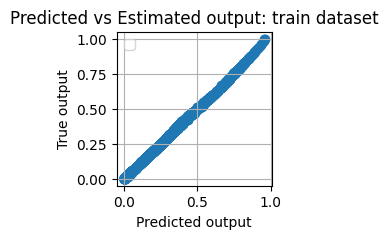

Training results
rmse = 0.0042. R2 = 1.000


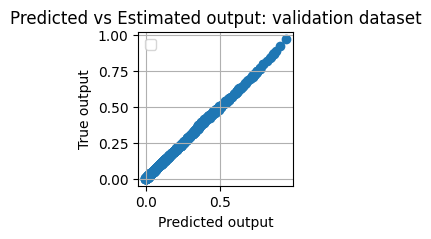

Validation results
rmse = 0.0043. R2 = 0.999


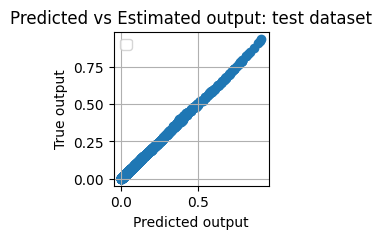

Test results
rmse = 0.0039. R2 = 1.000


In [290]:
# Assess results in training
rmse_train, R2_train = assess_results(model, X_train_tensor, y_train_tensor.view(-1,1), data_type = 'train')
print('Training results')
print(f"rmse = {rmse_train:.4f}. R2 = {R2_train:.3f}")

# Assess results in validation
rmse_val, R2_val = assess_results(model, X_val_tensor, y_val_tensor.view(-1,1), data_type = 'validation')
print('Validation results')
print(f"rmse = {rmse_val:.4f}. R2 = {R2_val:.3f}")

# Assess results in test
rmse_test, R2_test = assess_results(model, X_test_tensor, y_test_tensor.view(-1,1), data_type = 'test')
print('Test results')
print(f"rmse = {rmse_test:.4f}. R2 = {R2_test:.3f}")

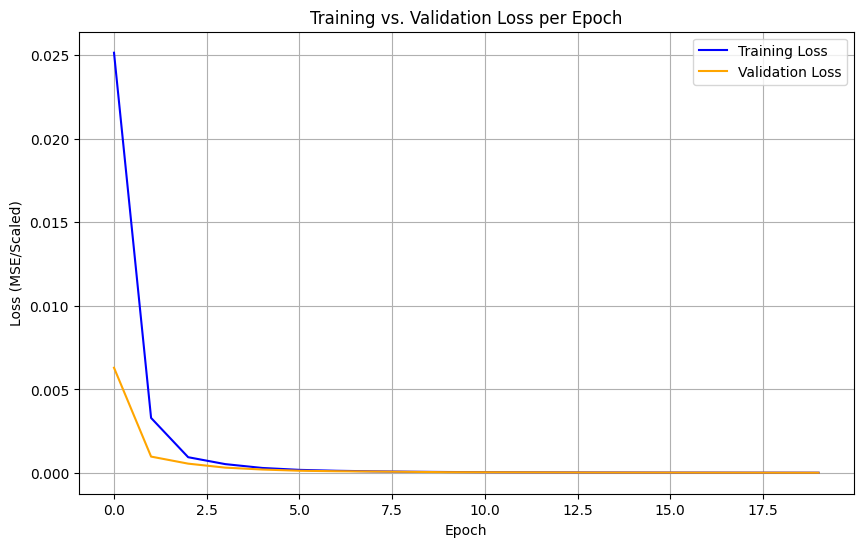

Final Training Loss: 0.000019
Final Validation Loss: 0.000018
Final Test Loss: 0.0000


In [291]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Plotting both on the same axes
plt.plot(train_loss, label='Training Loss', color='blue')
plt.plot(val_loss, label='Validation Loss', color='orange')

# Training and Validation Plot
plt.title('Training vs. Validation Loss per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE/Scaled)')
plt.legend()
plt.grid(True)
plt.show()


print(f"Final Training Loss: {train_loss[-1]:.6f}")
print(f"Final Validation Loss: {val_loss[-1]:.6f}")
print(f"Final Test Loss: {test_loss[-1]:.4f}")

### Assessment and inference

In [359]:
k = 25 # points to extract

valoriINP_ogni_100 = X_test_tensor[::k] #sono normalizzati
valoriINP_ogni_100.shape
true_val_ogni_100 = y_test_tensor[::k] #sono normalizzati

# scaled them back to BIG VALUES
true_val_ogni_100_unscaled = scaler_y.inverse_transform(true_val_ogni_100.cpu().numpy())
#print(valoriINP_ogni_100)
print(true_val_ogni_100_unscaled)

[[ 48054.117 ]
 [ 13946.638 ]
 [129342.5   ]
 [  1759.0029]
 [113237.54  ]
 [ 44931.25  ]
 [ 10981.282 ]
 [ 60329.41  ]
 [ 46656.473 ]
 [ 97569.17  ]
 [128946.47  ]
 [ 64444.7   ]
 [   791.2343]
 [ 51899.48  ]
 [ 18072.977 ]
 [ 26564.816 ]
 [ 29922.152 ]
 [ 28917.945 ]
 [ 49122.79  ]
 [ 56268.85  ]
 [ 37069.484 ]
 [ 10727.889 ]
 [  2353.5295]
 [ 56671.652 ]
 [  9006.271 ]
 [ 60148.62  ]
 [ 57199.055 ]
 [ 89715.516 ]
 [ 26774.055 ]
 [ 18688.777 ]
 [134092.23  ]
 [ 32918.438 ]
 [151614.97  ]
 [ 20483.887 ]
 [111247.42  ]
 [ 57851.484 ]
 [ 30332.15  ]
 [  6477.239 ]
 [  3606.5579]
 [ 82266.695 ]
 [  7129.28  ]
 [ 42783.82  ]
 [ 59158.887 ]
 [ 55727.414 ]
 [ 17313.393 ]
 [ 58939.277 ]
 [ 10512.743 ]
 [  4426.412 ]
 [  8735.972 ]
 [ 36085.418 ]]


In [293]:
# predizione

pred_vec_ogni_100 = model(valoriINP_ogni_100)
print(pred_vec_ogni_100.shape)
print(pred_vec_ogni_100)

torch.Size([50, 1])
tensor([[0.17948753],
        [0.05309717],
        [0.49801069],
        [0.00644007],
        [0.43202317],
        [0.17486271],
        [0.04319922],
        [0.23929679],
        [0.18050018],
        [0.36404335],
        [0.49688494],
        [0.25019726],
        [0.00641809],
        [0.20364761],
        [0.06908173],
        [0.10304818],
        [0.11097538],
        [0.10895673],
        [0.19429752],
        [0.22280952],
        [0.14610615],
        [0.03777226],
        [0.00452442],
        [0.22418591],
        [0.03221849],
        [0.23507613],
        [0.22390175],
        [0.34956643],
        [0.10083718],
        [0.07042307],
        [0.53137857],
        [0.12503925],
        [0.59304541],
        [0.07761369],
        [0.41952443],
        [0.22832835],
        [0.11088986],
        [0.02376632],
        [0.01385064],
        [0.31377202],
        [0.02381281],
        [0.16345727],
        [0.23245737],
        [0.21667334],
        [0.0

In [361]:
# scaliamo indietro i valori predetti per riportarli alla scala originale
with torch.no_grad():
    pred_vec_ogni_100_unscaled = scaler_y.inverse_transform(pred_vec_ogni_100.cpu().numpy())
    print(pred_vec_ogni_100_unscaled)

[[ 46618.98  ]
 [ 13914.379 ]
 [129039.62  ]
 [  1841.4498]
 [111964.77  ]
 [ 45422.27  ]
 [ 11353.199 ]
 [ 62095.15  ]
 [ 46881.016 ]
 [ 94374.41  ]
 [128748.32  ]
 [ 64915.742 ]
 [  1835.7626]
 [ 52870.613 ]
 [ 18050.523 ]
 [ 26839.639 ]
 [ 28890.87  ]
 [ 28368.527 ]
 [ 50451.195 ]
 [ 57828.926 ]
 [ 37981.26  ]
 [  9948.927 ]
 [  1345.7592]
 [ 58185.08  ]
 [  8511.842 ]
 [ 61003.016 ]
 [ 58111.547 ]
 [ 90628.375 ]
 [ 26267.521 ]
 [ 18397.607 ]
 [137673.84  ]
 [ 32530.018 ]
 [153630.67  ]
 [ 20258.242 ]
 [108730.62  ]
 [ 59256.97  ]
 [ 28868.74  ]
 [  6324.7676]
 [  3758.9993]
 [ 81366.266 ]
 [  6336.798 ]
 [ 42471.016 ]
 [ 60325.387 ]
 [ 56241.137 ]
 [ 17631.459 ]
 [ 58744.277 ]
 [ 10158.91  ]
 [  4688.6343]
 [  8581.415 ]
 [ 35900.926 ]]


In [362]:
# the bisettrice

xbis = np.linspace(0, 160000, 100)
ybis = xbis

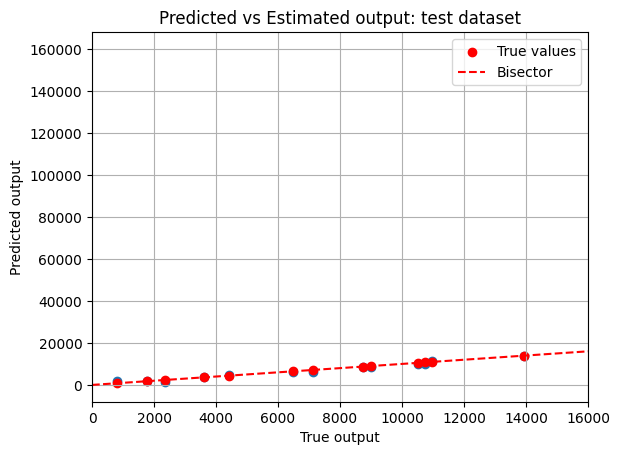

In [375]:
# plot on a big figure
with torch.no_grad():
    plt.Figure(figsize=(15, 16))
    plt.scatter(true_val_ogni_100_unscaled, pred_vec_ogni_100_unscaled)
    plt.scatter(true_val_ogni_100_unscaled, true_val_ogni_100_unscaled, color='red', label='True values')
    plt.xlabel('True output')
    plt.ylabel('Predicted output')
    plt.title(f'Predicted vs Estimated output: test dataset')  # Fixed f-string
    plt.plot(xbis,ybis, 'r--', label='Bisector')
    plt.xlim(0, 16000)
    plt.legend()
    plt.grid(True)
    plt.show()

In [377]:
# compute the error for every point
err_abs = np.abs(pred_vec_ogni_100_unscaled - true_val_ogni_100_unscaled)
print(np.argmax(err_abs))
err_rel = np.abs(pred_vec_ogni_100_unscaled - true_val_ogni_100_unscaled) / np.abs(true_val_ogni_100_unscaled)
print(err_rel*100)
print(np.max(err_rel*100))
print(np.argmax(err_rel*100))

Mn_err_rel = np.mean(err_rel)
print(f"Mean relative error: {Mn_err_rel*100:.2f}%")
Mn_err_abs = np.mean(err_abs)
print(f"Mean absolute error: {Mn_err_abs:.2f}")



30
[[2.98650098e+00]
 [2.31301546e-01]
 [2.34171137e-01]
 [4.68713808e+00]
 [1.12397861e+00]
 [1.09282410e+00]
 [3.38682675e+00]
 [2.92682838e+00]
 [4.81268615e-01]
 [3.27435946e+00]
 [1.53667212e-01]
 [7.30925858e-01]
 [1.32012512e+02]
 [1.87118018e+00]
 [1.24235906e-01]
 [1.03453481e+00]
 [3.44655442e+00]
 [1.89992046e+00]
 [2.70425653e+00]
 [2.77253604e+00]
 [2.45964408e+00]
 [7.26109219e+00]
 [4.28195343e+01]
 [2.67051649e+00]
 [5.48983765e+00]
 [1.42047238e+00]
 [1.59529245e+00]
 [1.01750445e+00]
 [1.89188087e+00]
 [1.55799341e+00]
 [2.67100430e+00]
 [1.17994642e+00]
 [1.32948816e+00]
 [1.10157084e+00]
 [2.26234889e+00]
 [2.42946982e+00]
 [4.82461691e+00]
 [2.35395360e+00]
 [4.22678423e+00]
 [1.09452522e+00]
 [1.11158762e+01]
 [7.31128454e-01]
 [1.97180867e+00]
 [9.21849072e-01]
 [1.83711195e+00]
 [3.30848992e-01]
 [3.36575317e+00]
 [5.92403412e+00]
 [1.76919806e+00]
 [5.11265218e-01]]
132.01251
12
Mean relative error: 5.75%
Mean absolute error: 837.29


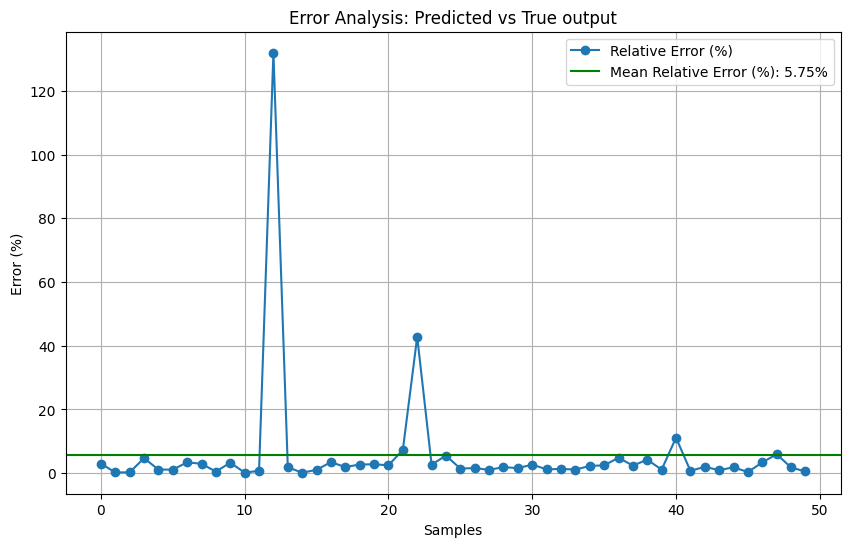

In [399]:
# plot the error with errorbars
plt.figure(figsize=(10, 6))
plt.plot(err_rel*100, 'o-', label='Relative Error (%)')
plt.axhline(y=Mn_err_rel*100, color='green', linestyle='-', label=f'Mean Relative Error (%): {Mn_err_rel*100:.2f}%')
plt.xlabel('Samples')
plt.ylabel('Error (%)')
plt.title('Error Analysis: Predicted vs True output')
plt.grid(True)
plt.legend()

plt.show()

In [383]:
import numpy as np

# 1. Definisci la terna che stai cercando
L_cercato = 2.6000000e+01      # corrispondente a TPU_L_mm
x_cercato = 2.3998341e-02      # corrispondente a x_coord_m
B_cercato = 5.9224092e-03      # corrispondente a B_val_T

# 2. Crea la maschera di confronto con tolleranza (np.isclose)
maschera = (
    np.isclose(df_senza_zero['TPU_L_mm'], L_cercato) & 
    np.isclose(df_senza_zero['x_coord_m'], x_cercato) & 
    np.isclose(df_senza_zero['B_val_T'], B_cercato)
)

# 3. Estrai la riga (o le righe) dal DataFrame originale
riga_trovata = df_senza_zero[maschera]

# 4. Mostra il risultato
print("Riga trovata nel dataset:")
print(riga_trovata)

Riga trovata nel dataset:
       B_magn_T  TPU_L_mm  t_index  x_coord_m   H_val_Am   B_val_T  blocco_id
55163  0.063158        26        1   0.023998  791.23433  0.005922          7


In [382]:
print(valoriINP_ogni_100[np.argmax(err_rel*100)])
print(true_val_ogni_100_unscaled[np.argmax(err_rel*100)])
print(scaler_X.inverse_transform(valoriINP_ogni_100.cpu().numpy())[np.argmax(err_rel*100)])

tensor([0.30000001, 0.63153529, 0.00410486])
[791.2343]
[2.6000000e+01 2.3998341e-02 5.9224092e-03]


### True Value

In [297]:
# extract a H(x) curve from the dataset for the same L and B_magn_T
x_dataset = df_senza_zero['x_coord_m'].values
x_dataset

array([0.        , 0.00053318, 0.00118007, ..., 0.035629  , 0.03692343,
       0.038     ], shape=(8208,))

In [298]:
condizione_reset = df_senza_zero["x_coord_m"] == 0
df_senza_zero["blocco_id"] = condizione_reset.cumsum()
df_senza_zero.head(40)

C:\Users\utente1\AppData\Local\Temp\ipykernel_8820\1585757329.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_senza_zero["blocco_id"] = condizione_reset.cumsum()


,B_magn_T,TPU_L_mm,t_index,x_coord_m,H_val_Am,B_val_T,blocco_id
43632,0.063158,20,1,0.000000,5511.493005,0.046150,1
43633,0.063158,20,1,0.000533,8645.906537,0.074075,1
43634,0.063158,20,1,0.001180,10368.532991,0.089480,1
43635,0.063158,20,1,0.001965,10892.623336,0.094368,1
43636,0.063158,20,1,0.002917,10724.646635,0.092789,1
43637,0.063158,20,1,0.004072,9980.915596,0.086014,1
43638,0.063158,20,1,0.005403,8846.235362,0.075867,1
43639,0.063158,20,1,0.006767,7657.554481,0.065237,1
43640,0.063158,20,1,0.008133,6559.358767,0.055416,1
43641,0.063158,20,1,0.009500,5580.454105,0.046753,1


In [490]:
# extract the 3 columns
df_plot = df_senza_zero[['B_magn_T','TPU_L_mm','x_coord_m','B_val_T','H_val_Am','blocco_id']]
df_plot_block = df_plot[df_plot['blocco_id'] == 256]
df_plot['blocco_id'].max()
df_plot_block.head(22)

,B_magn_T,TPU_L_mm,x_coord_m,B_val_T,H_val_Am,blocco_id
572973,0.821053,23,0.000000,0.545116,69809.914386,256
572974,0.821053,23,0.000614,0.800983,130860.509346,256
572975,0.821053,23,0.001354,0.880965,157676.502049,256
572976,0.821053,23,0.002251,0.883854,158721.900529,256
572977,0.821053,23,0.003337,0.848271,146437.632172,256
572978,0.821053,23,0.004655,0.785814,126187.592381,256
572979,0.821053,23,0.006171,0.705720,104198.083440,256
572980,0.821053,23,0.007754,0.623009,85401.159931,256
572981,0.821053,23,0.009340,0.544287,69657.890799,256
572982,0.821053,23,0.010925,0.471912,57199.056058,256


In [491]:
# extract the scalar real data:

# define the target u want:

B_magn_T_target_true = df_plot_block['B_magn_T'].iloc[0] # T
L_target_true = df_plot_block['TPU_L_mm'].iloc[0] # mm

print(f"Target B_magn_T: {B_magn_T_target_true} T, Target L: {L_target_true} mm")

Target B_magn_T: 0.821052631578947 T, Target L: 23 mm


In [492]:
# extract the H(x) curve for the same L and H_val_Am
vec_coord = df_plot_block['x_coord_m'].values
vec_H = df_plot_block['H_val_Am'].values

print(vec_coord.shape)
print(vec_H.shape)

(19,)
(19,)


Text(0.5, 1.0, 'REAL H(x) curve for L=23 mm and B_magn_T=0.821052631578947 T')

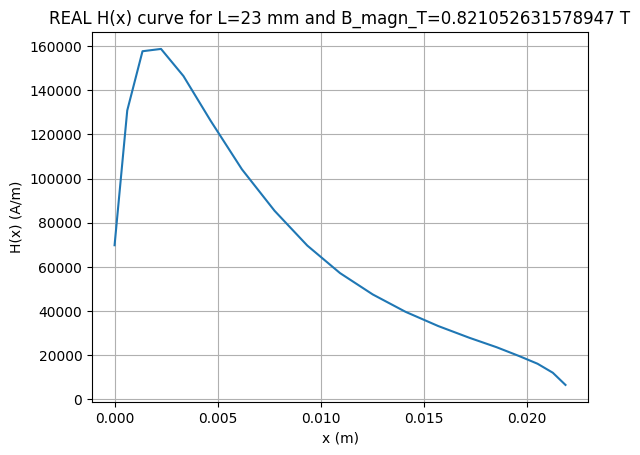

In [493]:
# do the plot

plt.figure()
plt.plot(vec_coord, vec_H, label='Real H(x) curve')
plt.grid(True)
plt.xlabel('x (m)')
plt.ylabel('H(x) (A/m)')  
plt.title(f'REAL H(x) curve for L={L_target_true} mm and B_magn_T={B_magn_T_target_true} T')

### Comparison

In [494]:
points_on_axis = 100
profile_of_B_target = df_plot_block['B_val_T'].values

dim_B_val = len(profile_of_B_target)
print(dim_B_val)
print(profile_of_B_target)

19
[0.54511624 0.80098262 0.88096473 0.88385445 0.84827133 0.78581421
 0.70571962 0.6230085  0.54428735 0.47191199 0.40635069 0.34662009
 0.29356276 0.24696996 0.20861746 0.17572032 0.14354133 0.10545092
 0.05535196]


In [495]:
print(L_target_true)

23


In [496]:
# reconstruction of the B(x) PREDICTED curve for a given L and B_magn_T

L_target_NN = L_target_true  # mm
B_magn_T_target_NN = B_magn_T_target_true # T

# get 20 points along such L
x_points = torch.linspace(0, L_target_NN/1000, dim_B_val) #len(vec_coord)

# shape check
print(x_points.shape)
print(x_points)
print(L_target_NN)

torch.Size([19])
tensor([0.00000000, 0.00127778, 0.00255556, 0.00383333, 0.00511111, 0.00638889,
        0.00766667, 0.00894444, 0.01022222, 0.01150000, 0.01277778, 0.01405556,
        0.01533333, 0.01661111, 0.01788889, 0.01916667, 0.02044445, 0.02172222,
        0.02300000])
23


In [497]:
# set the input dataset

matrice_input = np.zeros((dim_B_val, 3)) # len(vec_coord)

# Inserisci x_points nella prima colonna
matrice_input[:, 1] = x_points

# Assegni i valori scalari alle altre colonne (PyTorch li ripete in automatico)
matrice_input[:, 0] = L_target_NN
matrice_input[:, 2] = profile_of_B_target #profile_of_B_target_NN

X_input_scaled = scaler_X.transform(matrice_input)

# 4. SOLO ORA converti il risultato finale in un Tensor di PyTorch per la tua NN
X_input_tensor = torch.from_numpy(X_input_scaled).to(torch.float32)


print(matrice_input)
print(X_input_tensor)


[[2.30000000e+01 0.00000000e+00 5.45116236e-01]
 [2.30000000e+01 1.27777783e-03 8.00982619e-01]
 [2.30000000e+01 2.55555566e-03 8.80964731e-01]
 [2.30000000e+01 3.83333350e-03 8.83854453e-01]
 [2.30000000e+01 5.11111133e-03 8.48271333e-01]
 [2.30000000e+01 6.38888916e-03 7.85814210e-01]
 [2.30000000e+01 7.66666699e-03 7.05719624e-01]
 [2.30000000e+01 8.94444436e-03 6.23008502e-01]
 [2.30000000e+01 1.02222227e-02 5.44287346e-01]
 [2.30000000e+01 1.14999991e-02 4.71911992e-01]
 [2.30000000e+01 1.27777774e-02 4.06350688e-01]
 [2.30000000e+01 1.40555557e-02 3.46620090e-01]
 [2.30000000e+01 1.53333331e-02 2.93562760e-01]
 [2.30000000e+01 1.66111104e-02 2.46969959e-01]
 [2.30000000e+01 1.78888887e-02 2.08617459e-01]
 [2.30000000e+01 1.91666670e-02 1.75720325e-01]
 [2.30000000e+01 2.04444453e-02 1.43541331e-01]
 [2.30000000e+01 2.17222217e-02 1.05450921e-01]
 [2.30000000e+01 2.30000000e-02 5.53519559e-02]]
tensor([[0.15000001, 0.00000000, 0.48397392],
        [0.15000001, 0.03362573, 0.711688

C:\Users\utente1\AppData\Local\Temp\ipykernel_8820\2599566222.py:6: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  matrice_input[:, 1] = x_points


In [498]:
print(X_input_tensor)
print(L_target_NN)

tensor([[0.15000001, 0.00000000, 0.48397392],
        [0.15000001, 0.03362573, 0.71168864],
        [0.15000001, 0.06725147, 0.78287071],
        [0.15000001, 0.10087720, 0.78544247],
        [0.15000001, 0.13450293, 0.75377440],
        [0.15000001, 0.16812867, 0.69818914],
        [0.15000001, 0.20175439, 0.62690693],
        [0.15000001, 0.23538011, 0.55329609],
        [0.15000001, 0.26900586, 0.48323622],
        [0.15000001, 0.30263156, 0.41882399],
        [0.15000001, 0.33625731, 0.36047605],
        [0.15000001, 0.36988303, 0.30731732],
        [0.15000001, 0.40350875, 0.26009759],
        [0.15000001, 0.43713447, 0.21863116],
        [0.15000001, 0.47076023, 0.18449840],
        [0.15000001, 0.50438595, 0.15522078],
        [0.15000001, 0.53801173, 0.12658226],
        [0.15000001, 0.57163739, 0.09268276],
        [0.15000001, 0.60526317, 0.04809592]])
23


In [499]:
model.eval()
with torch.no_grad():
    y_input = model(X_input_tensor)
print(y_input.shape)
print(y_input)

torch.Size([19, 1])
tensor([[0.26955700],
        [0.51364166],
        [0.62033981],
        [0.62405884],
        [0.57154858],
        [0.48311701],
        [0.39113170],
        [0.32320306],
        [0.27019140],
        [0.22455639],
        [0.18493599],
        [0.15087610],
        [0.12783062],
        [0.10758240],
        [0.09081464],
        [0.07521536],
        [0.05994061],
        [0.04237203],
        [0.02253833]])


In [500]:
# torna inidetro ai valori SCALATI
y_input_unscaled = scaler_y.inverse_transform(y_input.cpu().numpy())
print(y_input_unscaled)

[[ 69925.24  ]
 [133084.27  ]
 [160693.33  ]
 [161655.67  ]
 [148068.17  ]
 [125185.75  ]
 [101383.75  ]
 [ 83806.625 ]
 [ 70089.4   ]
 [ 58280.94  ]
 [ 48028.816 ]
 [ 39215.527 ]
 [ 33252.31  ]
 [ 28012.906 ]
 [ 23674.104 ]
 [ 19637.654 ]
 [ 15685.181 ]
 [ 11139.156 ]
 [  6007.0146]]


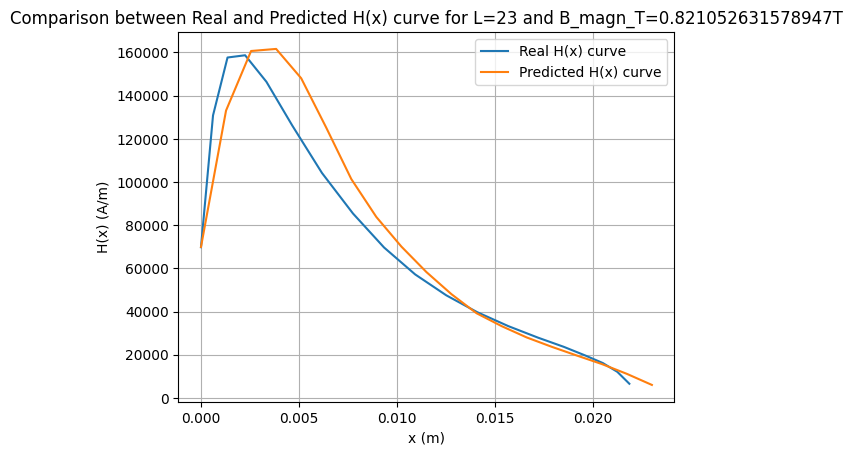

In [501]:
# comparison between the real B(x) curve and the predicted one  

plt.figure()
plt.plot(vec_coord, vec_H, label='Real H(x) curve')
plt.plot(x_points.numpy(), y_input_unscaled, label='Predicted H(x) curve')
plt.title(f'Comparison between Real and Predicted H(x) curve for L={L_target_true} and B_magn_T={B_magn_T_target_true}T')
plt.grid(True)
plt.xlabel('x (m)')
plt.ylabel('H(x) (A/m)')
plt.legend()    

In [502]:
vec_H.shape
y_input_unscaled.shape

(19, 1)

In [507]:
# mean error on the curve

err_abs_curve  = vec_H.reshape(-1) - y_input_unscaled.reshape(-1)
err_rel_curve = np.abs(vec_H.reshape(-1) - y_input_unscaled.reshape(-1)) / np.abs(vec_H.reshape(-1))
err_rel_curve_percentage = err_rel_curve * 100
print(f'the mean relative error of the predicted curve is: {np.mean(err_rel_curve_percentage):.2f}%')
print(err_rel_curve_percentage)


the mean relative error of the predicted curve is: 1.92%
[0.16520261 1.69933335 1.91330099 1.84837211 1.11347041 0.79393097
 2.70094549 1.86711156 0.61946699 1.89143916 1.05543177 1.16448755
 0.06046854 0.43661845 0.19588988 0.0534051  2.85017435 7.72720474
 8.32058372]
